# Machine learning Citiz : exploration, modèle, impact environnemental

**Question** : pour chaque carreau de 200 m d'Auvergne-Rhône-Alpes, une nouvelle station (Citiz, vélo, arrêt de bus) y serait-elle utile, et qu'est-ce qu'elle apporterait (habitants desservis, CO₂ évité) ?

**Données** : `data/gold/gold_features.csv`, produit par `model/build_features.py` (312 143 carreaux × 61 colonnes, tout en CSV).

Plan du notebook :
1. Chargement et dictionnaire des colonnes
2. Analyse exploratoire : valeurs manquantes, distributions, cibles, carte
3. Corrélations : matrice, redondances, lien avec les cibles
4. Modèles : références simples, LightGBM, validation par EPCI
5. Lecture du modèle : importance des variables (SHAP)
6. Impact environnemental : CO₂ évité par station Citiz (ratios ADEME)
7. Équité et éthique : qui profite des meilleurs sites
8. Points à discuter ensemble

Lancement : n'importe où dans le dépôt, avec un noyau basé sur `py` (pas le `.venv`, bloqué sur certains postes) : `py -m jupyter lab`. Bibliothèques : pandas, numpy, matplotlib, scipy, scikit-learn, lightgbm (`py -m pip install ...`).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 200)
plt.rcParams["figure.dpi"] = 110

# racine du dépôt : premier dossier parent qui contient data/gold (marche depuis la racine, model/ ou eda-citiz/)
RACINE = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "gold").is_dir()), Path.cwd())
GOLD = RACINE / "data" / "gold"
GRAINE = 42
print("racine :", RACINE)

racine : C:\Users\bilel\Desktop\epitech\T-HAK-700-MAR-7-1-hack-7


## 1. Chargement et dictionnaire des colonnes

In [2]:
df = pd.read_csv(GOLD / "gold_features.csv",
                 dtype={"code_commune": str, "code_epci": str, "CATEAAV2020": str, "grille_densite": str})
print(df.shape)
df.head(3)

(312143, 61)


,id_carreau,population,revenu,part_menages_sans_voiture,pop_400m,menages_400m,nb_carreaux_habites_400m,menages_sans_voiture_400m,part_sans_voiture_400m,revenu_400m,part_moins_18_400m,part_18_39_400m,part_40_64_400m,part_65_plus_400m,emplois_400m,nb_equipements_400m,nb_equip_services_400m,nb_equip_commerces_400m,nb_equip_enseignement_400m,nb_equip_sante_400m,nb_equip_transports_400m,nb_equip_sports_culture_400m,nb_equip_tourisme_400m,donnee_masquee,nb_arrets_400m,passages_jour_400m,nb_arrets_lourds_400m,dist_arret_lourd_m,dist_arret_m,dist_equip_transport_m,nb_stations_velo_400m,nb_autopartage_autre_400m,nb_bornes_300m,nb_bornes_7kw_300m,dist_borne_m,code_commune,pop_commune,densite_commune,grille_densite,territoire,CATEAAV2020,pop_aire,code_epci,pole,cible_citiz,cible_velo,cible_bus_passages_jour,info_dist_citiz_m,info_dist_velo_m,info_x_l93,info_y_l93,info_lon,info_lat,info_statut_couverture,info_pop_5min_pied,info_pop_gagnee_citiz,info_deja_desservi_citiz,info_pop_gagnee_bus,info_deja_desservi_bus,info_pop_gagnee_velo,info_deja_desservi_velo
0,CRS3035RES200mN2344800E3959000,7.0,23691.0,0.0625,7.0,3.2,1.0,0.2000,0.0625,23691.0,0.1714,0.1,0.2857,0.4429,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,0.0,0.0,0.0,114755.2009,62986.3764,7331.2625,0.0,0.0,0.0,0.0,7043.2767,26135,122,4.1302,3,4 hors aire · hors aire,30,NaN,200035723,0,0,0,NaN,79659.7100,96857.1439,898951.9,6338352.5,5.4860,44.1160,non_calcule,NaN,NaN,0,NaN,0,NaN,0
1,CRS3035RES200mN2345000E3958600,2.0,23691.0,0.0625,2.0,0.9,1.0,0.0562,0.0625,23691.0,0.1500,0.1,0.3000,0.4500,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,0.0,0.0,0.0,114644.5204,62540.3359,6983.6049,0.0,0.0,0.0,0.0,6707.0396,26135,122,4.1302,3,4 hors aire · hors aire,30,NaN,200035723,0,0,0,NaN,79541.9864,96521.7650,898536.6,6338515.4,5.4809,44.1176,non_calcule,NaN,NaN,0,NaN,0,NaN,0
2,CRS3035RES200mN2345000E3960400,1.0,24802.0,0.0625,1.0,0.5,1.0,0.0312,0.0625,24802.0,0.2000,0.3,0.4000,0.1000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,0.0,0.0,0.0,114271.2817,64136.9600,7871.2478,0.0,0.0,0.0,0.0,7539.5902,26135,122,4.1302,3,4 hors aire · hors aire,30,NaN,200035723,0,0,0,NaN,79202.1064,97208.2839,900325.7,6338680.4,5.5033,44.1185,ok,1.0,1.0,0,1.0,0,1.0,0


Trois familles de colonnes :
- **variables explicatives** : ce qui décrit le lieu et son entourage à 400 m (≈ 5 min à pied) ;
- **`cible_*`** : ce que les modèles apprennent, jamais utilisé comme variable ;
- **`info_*`** : utile à l'optimiseur ou à l'affichage, exclu du modèle (fuite de la cible : par exemple la distance à la station Citiz la plus proche).

In [3]:
IDS = ["id_carreau", "code_commune", "code_epci"]
CIBLES = [c for c in df.columns if c.startswith("cible_")]
INFOS = [c for c in df.columns if c.startswith("info_")]
CATEGORIES = ["territoire", "grille_densite", "CATEAAV2020"]
VARIABLES = [c for c in df.columns if c not in IDS + CIBLES + INFOS]
NUMERIQUES = [c for c in VARIABLES if c not in CATEGORIES]
print(f"{len(VARIABLES)} variables ({len(NUMERIQUES)} numériques), {len(CIBLES)} cibles, {len(INFOS)} infos")
print("cibles :", CIBLES)

41 variables (38 numériques), 3 cibles, 14 infos
cibles : ['cible_citiz', 'cible_velo', 'cible_bus_passages_jour']


## 2. Analyse exploratoire
### 2.1 Valeurs manquantes et statistiques

In [4]:
manq = df.isna().mean().sort_values(ascending=False)
manq[manq > 0].round(3).to_frame("part_manquante")

,part_manquante
cible_bus_passages_jour,0.903
info_pop_5min_pied,0.327
info_pop_gagnee_bus,0.313
info_pop_gagnee_velo,0.312
info_pop_gagnee_citiz,0.312
pop_aire,0.230


À lire : `cible_bus_passages_jour` n'est renseignée que là où un arrêt est à moins de 200 m (c'est voulu). Les colonnes `info_*` de couverture à pied sont vides pour les 97 462 candidats que le réseau piéton du rôle 2 ne sait pas raccorder (centre à plus de 50 m d'une voie).

In [5]:
df[NUMERIQUES].describe(percentiles=[.5, .9, .99]).T.round(2)

,count,mean,std,min,50%,90%,99%,max
population,312143.0,24.68,67.59,1.00,6.00,56.50,309.50,3846.50
revenu,312143.0,26163.04,5412.09,11162.00,25357.00,32634.80,44972.00,69913.00
part_menages_sans_voiture,312143.0,0.07,0.05,0.00,0.05,0.13,0.29,1.00
pop_400m,312143.0,239.64,609.97,1.00,61.00,557.50,2907.08,13493.50
menages_400m,312143.0,109.64,306.97,0.30,25.80,240.10,1443.00,7164.00
nb_carreaux_habites_400m,312143.0,6.45,3.12,1.00,6.00,11.00,13.00,13.00
menages_sans_voiture_400m,312143.0,17.41,105.07,0.00,1.25,18.89,355.53,4228.32
part_sans_voiture_400m,312143.0,0.07,0.05,0.00,0.05,0.13,0.28,0.84
revenu_400m,312143.0,25823.62,4951.08,12747.00,25087.00,31669.36,43337.46,59905.11
part_moins_18_400m,312143.0,0.20,0.06,0.00,0.20,0.27,0.34,0.50


### 2.2 Les carreaux sont très inégaux : la plupart sont presque vides

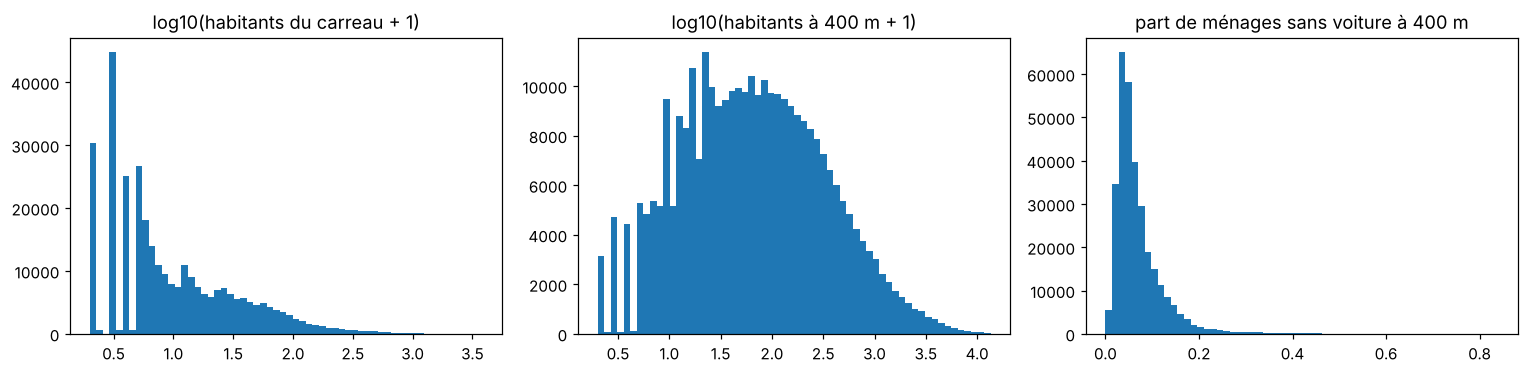

part des carreaux de moins de 20 habitants : 0.748


In [6]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
ax[0].hist(np.log10(df["population"] + 1), bins=60); ax[0].set_title("log10(habitants du carreau + 1)")
ax[1].hist(np.log10(df["pop_400m"] + 1), bins=60); ax[1].set_title("log10(habitants à 400 m + 1)")
ax[2].hist(df["part_sans_voiture_400m"], bins=60); ax[2].set_title("part de ménages sans voiture à 400 m")
plt.tight_layout(); plt.show()
print("part des carreaux de moins de 20 habitants :", round((df['population'] < 20).mean(), 3))

### 2.3 Les cibles

In [7]:
print("Citiz : carreaux positifs", df.cible_citiz.sum(), f"({df.cible_citiz.mean():.2%})")
print("Vélo  : carreaux positifs", df.cible_velo.sum(), f"({df.cible_velo.mean():.2%})")
print("Bus   : carreaux avec un arrêt à moins de 200 m", df.cible_bus_passages_jour.notna().sum())
par_terr = df.groupby("territoire").agg(carreaux=("id_carreau", "size"), habitants=("population", "sum"),
                                        citiz=("cible_citiz", "sum"), velo=("cible_velo", "sum"))
par_terr["citiz_pour_100k_hab"] = (par_terr.citiz / par_terr.habitants * 1e5).round(1)
par_terr.sort_index()

Citiz : carreaux positifs 1450 (0.46%)
Vélo  : carreaux positifs 2165 (0.69%)
Bus   : carreaux avec un arrêt à moins de 200 m 30308


,carreaux,habitants,citiz,velo,citiz_pour_100k_hab
territoire,,,,,
1 grande aire · couronne,81697,2303520.0,175,235,7.6
1 grande aire · pôle,10201,1897399.0,898,1317,47.3
2 aire moyenne · couronne,42181,691297.5,76,176,11.0
2 aire moyenne · pôle,5264,471440.5,200,309,42.4
3 petite aire · couronne,80724,945754.5,23,26,2.4
3 petite aire · pôle,20137,768333.5,52,97,6.8
4 hors aire · hors aire,71939,625810.5,26,5,4.2


Le déséquilibre est fort (≈ 1 carreau positif sur 200 pour Citiz). D'où le choix des métriques : **aire précision-rappel** et **rappel dans le top 1 %** plutôt que l'exactitude (prédire « jamais de station » donnerait 99,5 % d'exactitude).

### 2.4 Profil des lieux avec et sans station Citiz

In [8]:
cols = ["pop_400m", "part_sans_voiture_400m", "revenu_400m", "emplois_400m", "nb_equipements_400m",
        "passages_jour_400m", "dist_arret_lourd_m", "dist_equip_transport_m", "nb_stations_velo_400m",
        "nb_bornes_7kw_300m", "pop_commune"]
profil = df.groupby("cible_citiz")[cols].median().T
profil.columns = ["sans station", "avec station"]
profil["rapport"] = (profil["avec station"] / profil["sans station"].replace(0, np.nan)).round(1)
profil.round(2)

,sans station,avec station,rapport
pop_400m,60.50,3295.50,54.5
part_sans_voiture_400m,0.05,0.28,5.1
revenu_400m,25084.21,25873.03,1.0
emplois_400m,8.50,2179.15,256.4
nb_equipements_400m,1.00,154.50,154.5
passages_jour_400m,0.00,953.00,NaN
dist_arret_lourd_m,47027.40,751.99,0.0
dist_equip_transport_m,2120.28,199.99,0.1
nb_stations_velo_400m,0.00,0.00,NaN
nb_bornes_7kw_300m,0.00,2.00,NaN


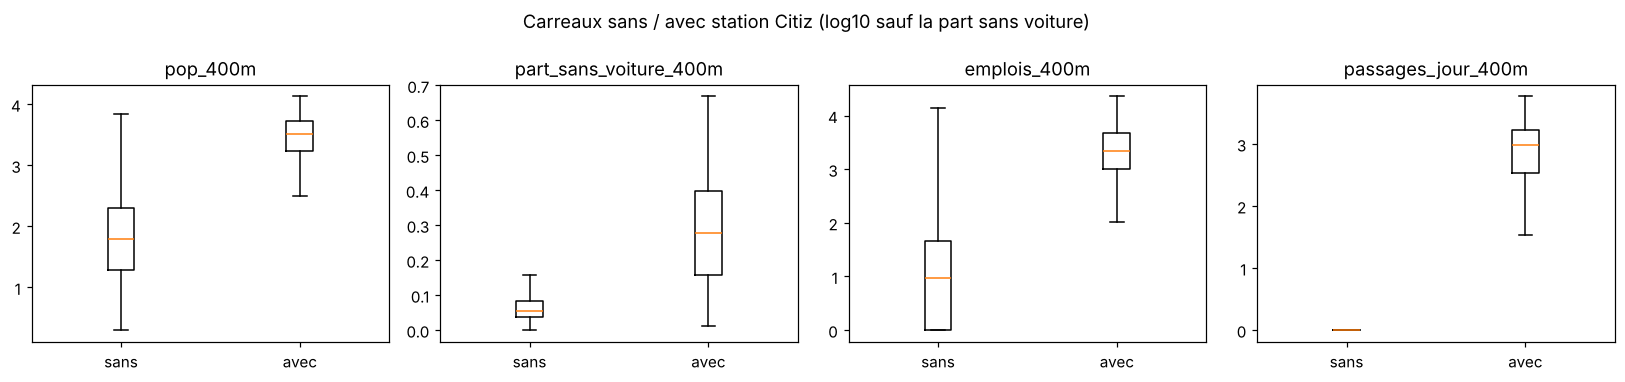

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.5))
for ax, c in zip(axes, ["pop_400m", "part_sans_voiture_400m", "emplois_400m", "passages_jour_400m"]):
    data = [np.log10(df.loc[df.cible_citiz == k, c] + 1) if c != "part_sans_voiture_400m"
            else df.loc[df.cible_citiz == k, c] for k in (0, 1)]
    ax.boxplot(data, showfliers=False); ax.set_xticks([1, 2], ["sans", "avec"]); ax.set_title(c)
plt.suptitle("Carreaux sans / avec station Citiz (log10 sauf la part sans voiture)"); plt.tight_layout(); plt.show()

### 2.5 Carte

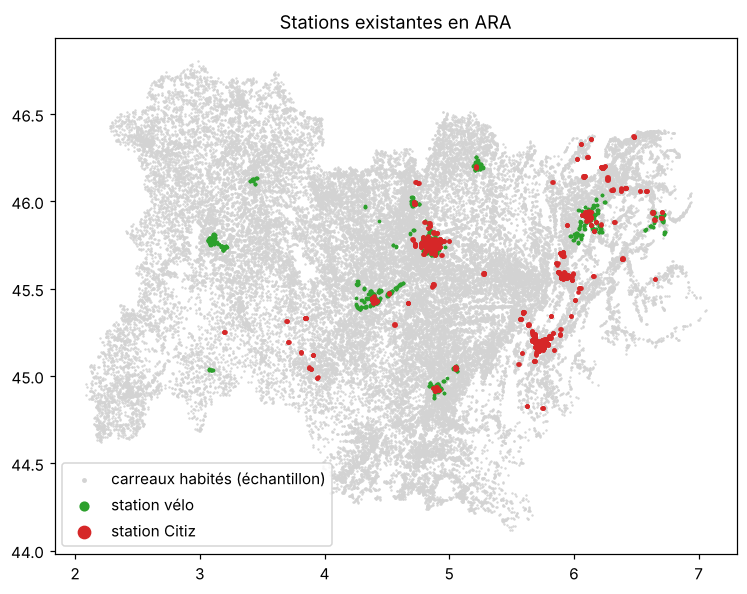

In [10]:
fig, ax = plt.subplots(figsize=(8, 8))
fond = df.sample(60000, random_state=GRAINE)
ax.scatter(fond.info_lon, fond.info_lat, s=0.3, c="lightgray", label="carreaux habités (échantillon)")
v = df[df.cible_velo == 1]; ax.scatter(v.info_lon, v.info_lat, s=2, c="tab:green", label="station vélo")
c = df[df.cible_citiz == 1]; ax.scatter(c.info_lon, c.info_lat, s=4, c="tab:red", label="station Citiz")
ax.set_aspect(1.4); ax.legend(markerscale=4); ax.set_title("Stations existantes en ARA"); plt.show()

## 3. Corrélations
### 3.1 Matrice de corrélation (Spearman)

Spearman plutôt que Pearson : les variables sont très asymétriques (quelques carreaux urbains énormes), et on cherche des liens monotones, pas linéaires. Calcul sur un échantillon de 60 000 carreaux pour la vitesse.

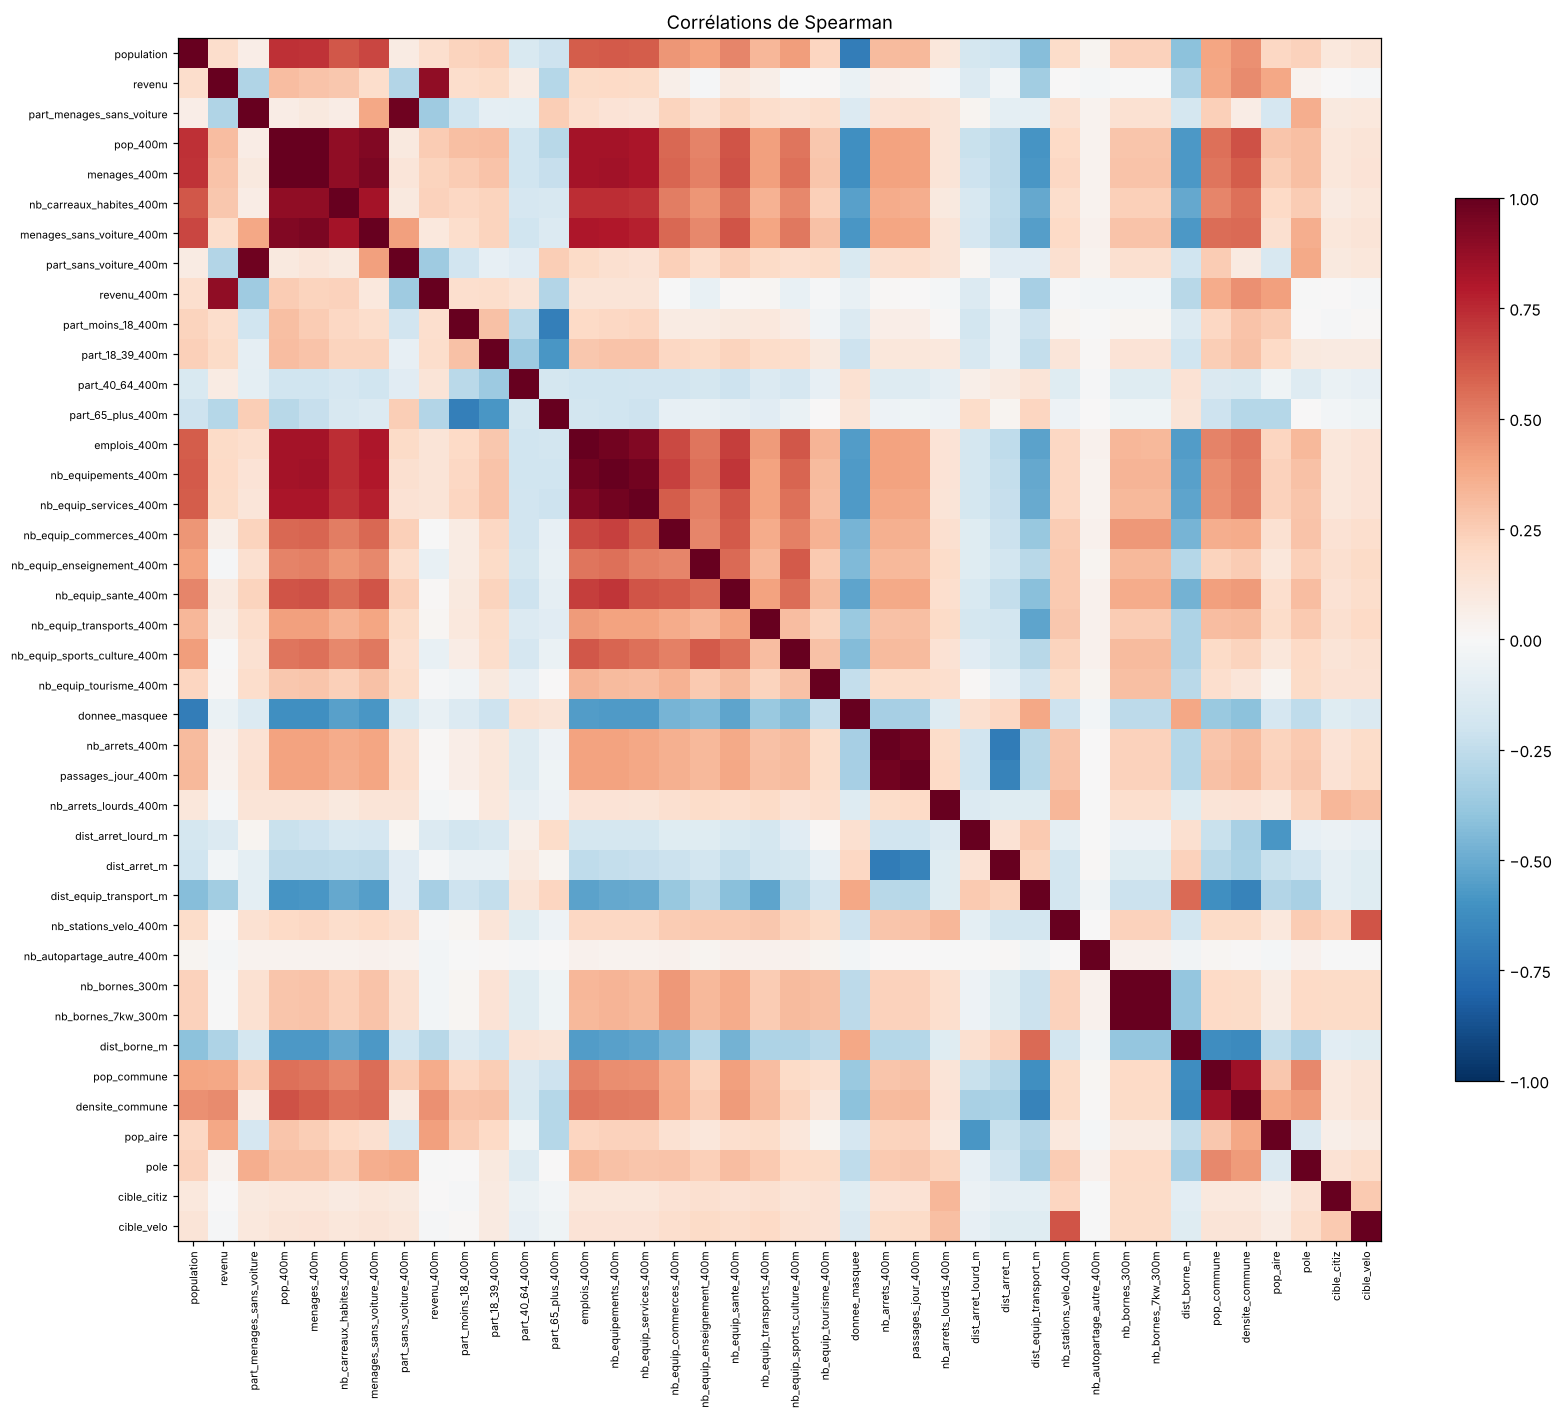

In [11]:
ech = df.sample(60000, random_state=GRAINE)
corr_cols = NUMERIQUES + ["cible_citiz", "cible_velo"]
corr = ech[corr_cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(15, 13))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_cols)), corr_cols, rotation=90, fontsize=7)
ax.set_yticks(range(len(corr_cols)), corr_cols, fontsize=7)
plt.colorbar(im, fraction=0.03); ax.set_title("Corrélations de Spearman"); plt.tight_layout(); plt.show()

### 3.2 Variables redondantes (|ρ| > 0,9)

In [12]:
paires = (corr.where(np.triu(np.ones(corr.shape, bool), k=1)).stack().rename("rho").reset_index())
paires.columns = ["variable_1", "variable_2", "rho"]
paires[paires.rho.abs() > 0.9].sort_values("rho", key=abs, ascending=False)

,variable_1,variable_2,rho
1272,nb_bornes_300m,nb_bornes_7kw_300m,0.998092
124,pop_400m,menages_400m,0.996569
87,part_menages_sans_voiture,part_sans_voiture_400m,0.970254
575,nb_equipements_400m,nb_equip_services_400m,0.967335
944,nb_arrets_400m,passages_jour_400m,0.965795
534,emplois_400m,nb_equipements_400m,0.965167
166,menages_400m,menages_sans_voiture_400m,0.940954
535,emplois_400m,nb_equip_services_400m,0.929667
126,pop_400m,menages_sans_voiture_400m,0.929616


Les arbres de décision supportent bien les variables redondantes (ils en choisissent une), mais l'importance se répartit entre elles : en lisant le SHAP plus bas, il faut regrouper les variables d'une même famille (population, ménages, emplois…).

### 3.3 Lien de chaque variable avec les cibles

In [13]:
lien = pd.DataFrame({
    "rho_citiz": corr["cible_citiz"].drop(["cible_citiz", "cible_velo"]),
    "rho_velo": corr["cible_velo"].drop(["cible_citiz", "cible_velo"]),
})
bus = df[df.cible_bus_passages_jour.notna()].sample(20000, random_state=GRAINE)
lien["rho_bus"] = [spearmanr(bus[c], bus.cible_bus_passages_jour, nan_policy="omit").statistic for c in lien.index]
lien.sort_values("rho_citiz", ascending=False).round(3)

,rho_citiz,rho_velo,rho_bus
nb_arrets_lourds_400m,0.333,0.299,0.267
nb_stations_velo_400m,0.217,0.629,0.365
nb_bornes_7kw_300m,0.192,0.191,0.272
nb_bornes_300m,0.192,0.191,0.275
nb_equip_transports_400m,0.157,0.198,0.443
nb_equip_enseignement_400m,0.156,0.191,0.394
pole,0.148,0.177,0.504
nb_equip_tourisme_400m,0.148,0.142,0.231
nb_equip_sante_400m,0.145,0.172,0.537
nb_equip_commerces_400m,0.144,0.169,0.485


À discuter : les variables les plus liées à la présence de Citiz sont la densité d'activité (emplois, équipements) et les transports, plus que le revenu. Une forte corrélation ne prouve pas que la variable *cause* le succès d'une station : Citiz s'est installé là où la densité est forte, et les transports y sont aussi.

## 4. Modèles

**Cible** : présence d'une station existante (Citiz ou vélo) à moins de 200 m, ou passages par jour de l'arrêt de bus proche. C'est une demande *révélée* par les choix passés des opérateurs, pas un usage mesuré : il n'existe aucune donnée de réservations par station.

**Validation** : par blocs géographiques. On coupe par **EPCI** (172 intercommunalités) en 5 plis : le modèle est toujours testé sur des territoires qu'il n'a jamais vus. Un découpage aléatoire des carreaux surestimerait la performance, car deux carreaux voisins sont presque identiques.

**Références à battre** : la population à 400 m, et la population × part de ménages sans voiture (≈ ménages sans voiture à 400 m).

In [14]:
import lightgbm as lgb
from sklearn.model_selection import GroupKFold
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve

for c in CATEGORIES:
    df[c] = df[c].astype("category")

# variables retirées par type, car elles décrivent la cible (fuite) ou une causalité inversée
FUITES = {
    "citiz": ["nb_bornes_300m", "nb_bornes_7kw_300m", "dist_borne_m"],  # bornes posées pour les stations Citiz
    "velo": ["nb_stations_velo_400m"],
    "bus": ["nb_arrets_400m", "passages_jour_400m", "nb_arrets_lourds_400m", "dist_arret_lourd_m", "dist_arret_m"],
}
# volontairement simple : avec ~1 500 positifs, des arbres profonds apprennent les villes par cœur
PARAMS = dict(n_estimators=300, learning_rate=0.03, num_leaves=7, min_child_samples=500, reg_lambda=10,
              subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=GRAINE, verbose=-1)

def rappel_top(y, s, part=0.01):
    k = max(1, int(len(s) * part))
    return y[np.argsort(-s)[:k]].sum() / max(y.sum(), 1)

def valider(t, params=PARAMS):
    cols = [c for c in VARIABLES if c not in FUITES[t]]
    d = df[df.cible_bus_passages_jour.notna()] if t == "bus" else df
    y = np.log1p(d.cible_bus_passages_jour.to_numpy()) if t == "bus" else d[f"cible_{t}"].to_numpy()
    oof, plis = np.zeros(len(d)), np.zeros(len(d), int)
    for k, (tr, te) in enumerate(GroupKFold(5).split(d, y, d.code_epci)):
        m = (lgb.LGBMRegressor if t == "bus" else lgb.LGBMClassifier)(**params).fit(d[cols].iloc[tr], y[tr])
        oof[te] = m.predict(d[cols].iloc[te]) if t == "bus" else m.predict_proba(d[cols].iloc[te])[:, 1]
        plis[te] = k
    return d, y, oof, plis, cols

def tableau(t, d, y, oof, plis):
    scores = {"LightGBM": oof, "réf. population": d.pop_400m.to_numpy(),
              "réf. pop × sans voiture": d.menages_sans_voiture_400m.to_numpy()}
    lignes = []
    for nom, s in scores.items():
        r = []
        for k in range(5):
            m = plis == k
            r.append({"spearman": spearmanr(y[m], s[m]).statistic} if t == "bus" else
                     {"aire_pr": average_precision_score(y[m], s[m]), "auc_roc": roc_auc_score(y[m], s[m]),
                      "rappel_top1pct": rappel_top(y[m], s[m])})
        r = pd.DataFrame(r)
        lignes.append({"modèle": nom, **{f"{c} (moy.)": r[c].mean() for c in r}, **{f"{c} (écart-type)": r[c].std() for c in r}})
    return pd.DataFrame(lignes).round(3)

resultats = {}
for t in ["citiz", "velo", "bus"]:
    resultats[t] = valider(t)
    print(f"=== {t} ===")
    display(tableau(t, *resultats[t][:4]))

=== citiz ===


,modèle,aire_pr (moy.),auc_roc (moy.),rappel_top1pct (moy.),aire_pr (écart-type),auc_roc (écart-type),rappel_top1pct (écart-type)
0,LightGBM,0.287,0.978,0.575,0.173,0.014,0.127
1,réf. population,0.191,0.957,0.468,0.142,0.022,0.111
2,réf. pop × sans voiture,0.217,0.962,0.452,0.162,0.013,0.105


=== velo ===


,modèle,aire_pr (moy.),auc_roc (moy.),rappel_top1pct (moy.),aire_pr (écart-type),auc_roc (écart-type),rappel_top1pct (écart-type)
0,LightGBM,0.309,0.962,0.476,0.156,0.044,0.110
1,réf. population,0.287,0.956,0.449,0.181,0.026,0.140
2,réf. pop × sans voiture,0.309,0.955,0.467,0.188,0.035,0.153


=== bus ===


,modèle,spearman (moy.),spearman (écart-type)
0,LightGBM,0.660,0.055
1,réf. population,0.600,0.036
2,réf. pop × sans voiture,0.581,0.053


À lire (résultats obtenus le 21/10) :
- **Citiz** : le modèle bat nettement les références (aire PR ≈ 0,29 contre 0,22 ; ≈ 57 % des stations retrouvées dans le top 1 % contre 47 %).
- **Vélo** : égalité avec la référence pop × sans voiture. On le dit honnêtement.
- **Bus** : gain modeste (Spearman ≈ 0,66 contre 0,60).
- L'écart-type entre plis est grand : un pli contient la métropole de Lyon, un autre surtout du rural. C'est normal et à montrer.
- Premier essai (31 feuilles, positifs repondérés) : **battu par la référence population**. C'est la raison du modèle simple.

### 4.1 Courbes précision-rappel (Citiz)

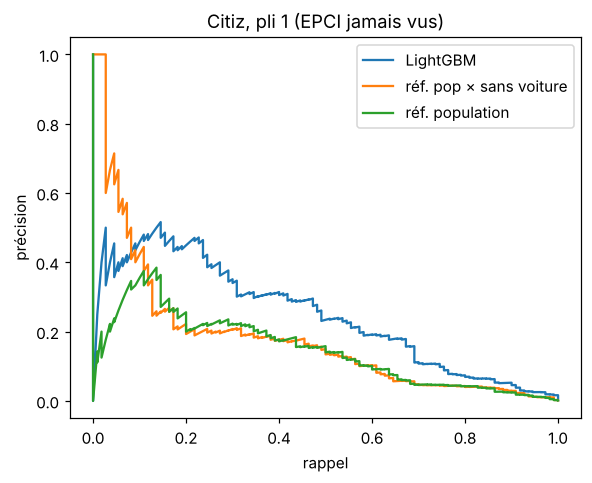

In [15]:
d, y, oof, plis, cols = resultats["citiz"]
fig, ax = plt.subplots(figsize=(6, 4.5))
for nom, s in {"LightGBM": oof, "réf. pop × sans voiture": d.menages_sans_voiture_400m.to_numpy(),
               "réf. population": d.pop_400m.to_numpy()}.items():
    m = plis == 0  # un pli, pour comparer des scores à la même échelle
    p, r, _ = precision_recall_curve(y[m], s[m]); ax.plot(r, p, label=nom)
ax.set_xlabel("rappel"); ax.set_ylabel("précision"); ax.set_title("Citiz, pli 1 (EPCI jamais vus)"); ax.legend(); plt.show()

### 4.2 Le modèle marche-t-il hors des grandes villes ?

In [16]:
rangs = pd.Series(oof).groupby(plis).rank(pct=True).to_numpy()
ref = pd.Series(d.menages_sans_voiture_400m.to_numpy()).groupby(plis).rank(pct=True).to_numpy()
lignes = []
for v in d.territoire.cat.categories:
    m = (d.territoire == v).to_numpy()
    if y[m].sum() >= 5:
        lignes.append({"territoire": v, "positifs": int(y[m].sum()), "aire_pr modèle": average_precision_score(y[m], rangs[m]),
                       "aire_pr référence": average_precision_score(y[m], ref[m])})
pd.DataFrame(lignes).round(3)

,territoire,positifs,aire_pr modèle,aire_pr référence
0,1 grande aire · couronne,175,0.187,0.052
1,1 grande aire · pôle,898,0.314,0.275
2,2 aire moyenne · couronne,76,0.182,0.140
3,2 aire moyenne · pôle,200,0.412,0.265
4,3 petite aire · couronne,23,0.023,0.006
5,3 petite aire · pôle,52,0.169,0.059
6,4 hors aire · hors aire,26,0.008,0.014


Le modèle bat la référence dans les petites villes-centres et les villes moyennes, ce qui compte pour la péréquation. Dans le rural hors aire d'attraction (26 positifs), personne n'apprend rien : il faudra un **quota rural** dans l'optimiseur plutôt que de se fier au score.

## 5. Lecture du modèle : importance des variables (SHAP)

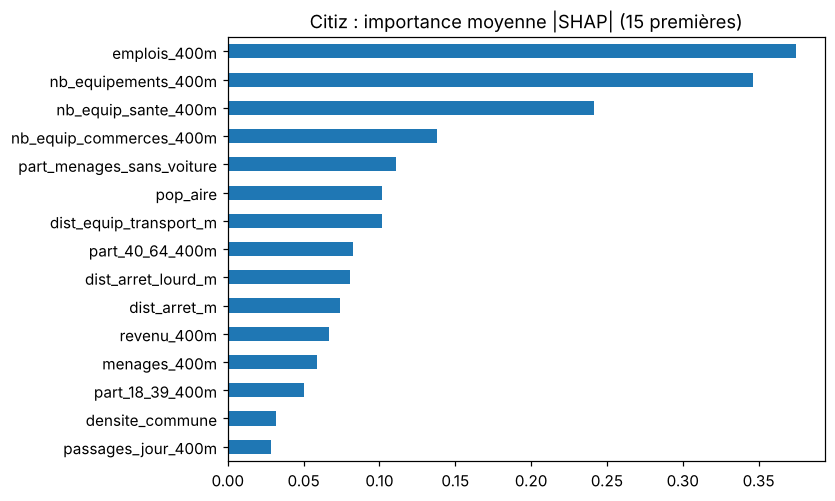

In [17]:
d, y, _, _, cols = resultats["citiz"]
final = lgb.LGBMClassifier(**PARAMS).fit(d[cols], y)
ech = d[cols].sample(20000, random_state=GRAINE)
contrib = final.predict_proba(ech, pred_contrib=True)[:, :-1]  # SHAP natif de LightGBM
imp = pd.Series(np.abs(contrib).mean(axis=0), index=cols).sort_values()
imp.tail(15).plot.barh(figsize=(7, 5), title="Citiz : importance moyenne |SHAP| (15 premières)"); plt.show()

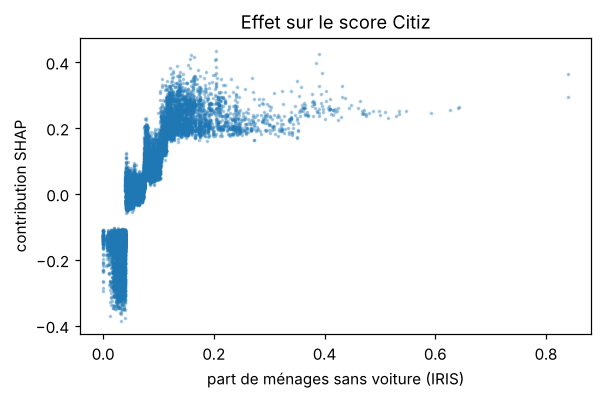

In [18]:
# effet de la part de ménages sans voiture sur le score (dépendance SHAP)
j = cols.index("part_menages_sans_voiture")
plt.figure(figsize=(6, 3.5)); plt.scatter(ech.iloc[:, j], contrib[:, j], s=2, alpha=.3)
plt.xlabel("part de ménages sans voiture (IRIS)"); plt.ylabel("contribution SHAP"); plt.title("Effet sur le score Citiz"); plt.show()

## 6. Impact environnemental : CO₂ évité par une station Citiz

Ratios de l'enquête nationale sur l'autopartage (ADEME, 2022) et facteurs d'émission de l'API Impact CO₂ (ADEME), relus dans `restitution/relecture_ratios_co2.md`. Un point reste ouvert : les 10 000 à 19 000 km évités par voiture partagée sont-ils **nets** ou **bruts** des km roulés par la voiture partagée elle-même ? On calcule les deux.

In [19]:
R = {  # valeur centrale, min, max
    "voitures_remplacees": (6.5, 5, 8),          # voitures privées remplacées par voiture partagée
    "km_evites": (14_500, 10_000, 19_000),       # km de voiture privée évités par voiture partagée et par an
    "km_parcourus": (15_130, 15_130, 15_130),    # km roulés par la voiture partagée
    "f_thermique": (0.1106, 0.094, 0.138),       # kg CO2e / km, voiture thermique
    "f_electrique": (0.0121, 0.0121, 0.0121),    # kg CO2e / km, voiture électrique
}
lignes = []
for scen, i in [("bas", 1), ("central", 0), ("haut", 2)]:
    evite = R["km_evites"][i] * R["f_thermique"][i] / 1000
    for vehicule, f in [("thermique", R["f_thermique"][i]), ("électrique", R["f_electrique"][i])]:
        propre = R["km_parcourus"][i] * f / 1000
        lignes.append({"scénario": scen, "véhicule partagé": vehicule, "t CO2 évitées (brut)": evite,
                       "émissions du véhicule partagé": propre, "t CO2 évitées (net)": evite - propre})
co2 = pd.DataFrame(lignes).round(2)
co2

,scénario,véhicule partagé,t CO2 évitées (brut),émissions du véhicule partagé,t CO2 évitées (net)
0,bas,thermique,0.94,1.42,-0.48
1,bas,électrique,0.94,0.18,0.76
2,central,thermique,1.60,1.67,-0.07
3,central,électrique,1.60,0.18,1.42
4,haut,thermique,2.62,2.09,0.53
5,haut,électrique,2.62,0.18,2.44


À discuter : si les km évités sont **bruts**, une voiture partagée **thermique** n'évite presque rien en net (≈ 1,6 − 1,7 t), alors qu'une **électrique** évite ≈ 1,4 t par an. C'est un argument fort pour l'électrique, à vérifier pages 80 à 82 du rapport ADEME avant de le mettre dans les slides. Autres effets du rapport : 6,5 voitures privées en moins et ≈ 2 places de stationnement libérées par voiture partagée.

### 6.1 CO₂ d'un portefeuille de nouvelles stations (illustration)

In [20]:
d, y, _, _, cols = resultats["citiz"]
df["score_citiz"] = final.predict_proba(df[cols])[:, 1]
# candidats : pas déjà desservis par Citiz à 5 min à pied, au moins 200 habitants gagnés
cand = df[(df.info_deja_desservi_citiz == 0) & (df.info_pop_gagnee_citiz >= 200)].copy()
N = 50
top = cand.nlargest(N, "score_citiz")
net_elec = co2.query("scénario == 'central' and `véhicule partagé` == 'électrique'")["t CO2 évitées (net)"].iloc[0]
print(f"{N} stations (1 véhicule électrique chacune) : {top.info_pop_gagnee_citiz.sum():,.0f} habitants gagnés à 5 min à pied")
print(f"CO2 évité ≈ {N * net_elec:,.0f} t/an (central, net) ; voitures privées en moins ≈ {N * R['voitures_remplacees'][0]:.0f}")
top[["code_commune", "territoire", "info_pop_gagnee_citiz", "score_citiz", "nb_bornes_7kw_300m"]].head(15)

50 stations (1 véhicule électrique chacune) : 45,885 habitants gagnés à 5 min à pied
CO2 évité ≈ 71 t/an (central, net) ; voitures privées en moins ≈ 325


,code_commune,territoire,info_pop_gagnee_citiz,score_citiz,nb_bornes_7kw_300m
183474,69123,1 grande aire · pôle,794.0,0.801830,4.0
181395,69123,1 grande aire · pôle,1079.0,0.795078,2.0
183469,69123,1 grande aire · pôle,791.0,0.787097,4.0
183071,69123,1 grande aire · pôle,502.5,0.781935,7.0
183905,69123,1 grande aire · pôle,224.5,0.779668,4.0
183470,69123,1 grande aire · pôle,791.0,0.778232,0.0
180995,69123,1 grande aire · pôle,2011.5,0.774840,10.0
183077,69123,1 grande aire · pôle,267.0,0.773855,13.0
183482,69123,1 grande aire · pôle,264.5,0.734045,4.0
183477,69123,1 grande aire · pôle,731.0,0.732560,12.0


Cette liste est une illustration (les 50 meilleurs scores, sans budget ni distance minimale entre stations). La vraie sélection sous budget, avec équilibre financier régional et quota hors grandes villes, est le rôle de l'optimiseur (`optim/optimise.py`).

## 7. Équité et éthique

In [21]:
part = pd.DataFrame({
    "part des habitants": df.groupby("territoire", observed=True).population.sum() / df.population.sum(),
    "part des stations Citiz actuelles": df.groupby("territoire", observed=True).cible_citiz.sum() / df.cible_citiz.sum(),
    f"part des {N} meilleurs candidats": top.territoire.value_counts(normalize=True),
}).fillna(0).round(3)
part

,part des habitants,part des stations Citiz actuelles,part des 50 meilleurs candidats
territoire,,,
1 grande aire · couronne,0.299,0.121,0.02
1 grande aire · pôle,0.246,0.619,0.74
2 aire moyenne · couronne,0.090,0.052,0.06
2 aire moyenne · pôle,0.061,0.138,0.18
3 petite aire · couronne,0.123,0.016,0.00
3 petite aire · pôle,0.100,0.036,0.00
4 hors aire · hors aire,0.081,0.018,0.00


À discuter :
- **Biais du modèle** : il apprend où Citiz est déjà. Sans contrainte, il propose surtout des pôles urbains et reproduit l'existant. D'où le **quota hors grandes villes** dans l'optimiseur, et un calcul du « coût de l'équité » (habitants desservis avec et sans quota).
- **Stigmatisation** : parler de « potentiel » et non de territoire « mal desservi ».
- **Vie privée** : ne pas afficher de score pour les carreaux de moins de 20 habitants (secret statistique Filosofi) ; la carte publique utilise les groupes O1 d'au moins 20 habitants.
- **Rural** : 97 462 candidats sont non calculables sur le réseau piéton (787 000 habitants, surtout peu denses). Les écarter de l'optimiseur pénaliserait le rural.

In [22]:
print("carreaux de moins de 20 habitants :", int((df.population < 20).sum()), "-> score non affiché sur la carte publique")
print(df.groupby(df.info_statut_couverture.fillna("absent")).population.agg(["size", "sum"]))

carreaux de moins de 20 habitants : 233523 -> score non affiché sur la carte publique
                          size        sum
info_statut_couverture                   
non_calcule              97462   786855.0
ok                      209953  6851153.5
partiel                   4728    65547.0


## 8. Points à discuter ensemble

1. **Cible** : garder « présence d'une station » (demande révélée), ou demander à Citiz les réservations par station pour une vraie cible d'usage ?
2. **Vélo** : le modèle n'apporte rien par rapport à la référence. On garde la référence pour le vélo ?
3. **CO₂** : km évités nets ou bruts (pages 80 à 82 du rapport ADEME) ? Ça change l'argument électrique.
4. **Quota hors grandes villes** dans l'optimiseur : quelle valeur (40 % proposé) ?
5. **Candidats non calculables** : leur garder une couverture à vol d'oiseau, marquée « estimée » ?
6. **Score → usage chiffré** (locations par jour) pour la marge et la péréquation : calibrer sur la moyenne Citiz (≈ 1 location par jour et par station) ?